In [66]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd

Understanding Data :

In [65]:
df = sns.load_dataset("titanic")

df["family_size"] = df["sibsp"] + df["parch"] + 1

print(f"First 5 Rows : \n{df.head(5)}")

print(f"Dataset Dimensions : \n{df.shape}")

print(f"Column Names And Data Types : \n{df.dtypes}")

print(f"Dataset Information : ")
df.info()

print(f"Descriptive Statistics : \n{df.describe()}")

print(f"Missing Values : \n{df.isnull().sum()}")

print(f"\nDuplicate Rows:\n{df.duplicated().sum()}")

First 5 Rows : 
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  family_size  
0    man        True  NaN  Southampton    no  False            2  
1  woman       False    C    Cherbourg   yes  False            2  
2  woman       False  NaN  Southampton   yes   True            1  
3  woman       False    C  Southampton   yes  False            2  
4    man        True  NaN  Southampton    no   True            1  
Dataset Dimensions : 
(891, 16)
Column Names And Data Types : 
survived          int64
pclass            int64
sex           

Defining Questions

In [71]:

df["age_group"] = "Old"
df.loc[df["age"]<18 , "age_group"] = "Child"
df.loc[((df["age"]>=18) & (df["age"]<=35)) , "age_group"] = "Young"
df.loc[((df["age"]>=36) & (df["age"]<=59)) , "age_group"] = "Middle_Aged"
df.loc[df["age"].isna() , "age_group"] = None
df.loc[df["age"]>=60 , "age_group"] = "Old"

df["fare_group"] = "above_average"
df.loc[df["fare"]<df["fare"].mean() , "fare_group"] = "below_average"

gender_survived = df.groupby("sex")["survived"].mean() * 100
age_group_survived = df.groupby("age_group")["survived"].mean()*100
class_survived = df.groupby("pclass")["survived"].mean()*100
fare_survived = df.groupby("fare_group")["survived"].mean()*100
alone_survived = df.groupby("alone")["survived"].mean()*100
family_size_survived = df.groupby("family_size")["survived"].mean()*100
family_size_class_survived = df.groupby(["pclass" , "family_size"])["survived"].mean()*100
embarkation_survived = df.groupby("embarked")["survived"].mean()*100

print(f"gender_survived :\n{gender_survived}\n")
print(f"age_group_survived :\n{age_group_survived}\n")
print(f"class_survived :\n{class_survived}\n")
print(f"fare_survived :\n{fare_survived}\n")
print(f"alone_survived :\n{alone_survived}\n")
print(f"family_size_survived :\n{family_size_survived}\n")
print(f"family_size_class :\n{family_size_class_survived}\n")
print(f"embarkation_survived :\n{embarkation_survived}\n")

gender_survived :
sex
female    74.203819
male      18.890814
Name: survived, dtype: float32

age_group_survived :
age_group
Child          51.685394
Middle_Aged    40.000000
Young          38.020836
Name: survived, dtype: float32

class_survived :
pclass
1.0    62.962959
2.0    47.282608
3.0    24.236254
Name: survived, dtype: float32

fare_survived :
fare_group
above_average    53.727509
below_average    26.494022
Name: survived, dtype: float32

alone_survived :
alone
False    50.564976
True     30.353817
Name: survived, dtype: float32

family_size_survived :
family_size
1.0     30.353817
2.0     55.279507
3.0     57.843136
4.0     72.413788
5.0     20.000000
6.0     13.636364
7.0     33.333336
8.0      0.000000
11.0     0.000000
Name: survived, dtype: float32

family_size_class :
pclass  family_size
1.0     1.0             53.211010
        2.0             72.857140
        3.0             75.000000
        4.0             71.428574
        5.0            100.000000
        6.0     

Data Cleaning

In [74]:
empty_data = df.isna().sum()

df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
df["embark_town"] = df["embark_town"].fillna(df["embark_town"].mode()[0])


print("Duplicate rows:", df.duplicated().sum())
print("Total rows:", len(df))

#survived_alive :

mask_survived = (df["survived"] != 0) & (df["survived"] != 1)
df.loc[mask_survived, "survived"] = np.nan 

mask_alive = (df["alive"] != "no") & (df["alive"] != "yes")
df.loc[mask_alive , "alive"] = np.nan

df.loc[df["survived"] == 0, "alive"] = "no"
df.loc[df["survived"] == 1, "alive"] = "yes"

#pclass_class :	

mask_pclass = (df["pclass"] != 1) & (df["pclass"] != 2) & (df["pclass"] != 3)
df.loc[mask_pclass , "pclass"] = np.nan

mask_class = (df["class"] != "First") & (df["class"] != "Second") & (df["class"] != "Third")
df.loc[mask_class , "class"] = np.nan

df.loc[df["pclass"] == 1, "class"] = "First"
df.loc[df["pclass"] == 2, "class"] = "Second"
df.loc[df["pclass"] == 3, "class"] = "Third"

#age :

std_age = df["age"].std()
mean_age = df["age"].mean()
mask_age = ((mean_age-(2*std_age))>df["age"])|((mean_age+(2*std_age))<df["age"])
df.loc[mask_age , "age"] = np.nan

#fare :

std_fare = df["fare"].std()
mean_fare = df["fare"].mean()
mask_fare = ((mean_fare-(2*std_fare))>df["fare"])|((mean_fare+(2*std_fare))<df["fare"])
df.loc[mask_fare , "fare"] = np.nan

#parch_sibs_familysize_alone :

mask_sibsp = (df["sibsp"] < 0)
df.loc[mask_sibsp, "sibsp"] = np.nan

mask_parch = (df["parch"] < 0)
df.loc[mask_parch, "parch"] = np.nan

mask_family_size = (df["family_size"] < 1)
df.loc[mask_family_size, "family_size"] = np.nan

mask_sibsp_parch_family_size_alone = (df["sibsp"]== 0) & (df["parch"] == 0) & (df["family_size"] == 1)
df.loc[mask_sibsp_parch_family_size_alone , "alone"] = True
df.loc[~mask_sibsp_parch_family_size_alone , "alone"] = False

#sex_who :

mask_sex = (df["sex"]!="male")&(df["sex"]!="female")
df.loc[mask_sex , "sex"] = np.nan

mask_who = ( (df["who"] != "man") & (df["who"] != "woman") & (df["who"] != "child") )
df.loc[mask_who, "who"] = np.nan

df.loc[(df["sex"] == "male") & (df["who"] == "woman"), "who"] = "man"
df.loc[(df["sex"] == "female") & (df["who"] == "man"), "who"] = "woman"

for i in colums_df:

    if df[i].dtype == "int64":

        if df[i].min() >= 0 and df[i].max() <= 255:
            df[i] = df[i].astype("uint8")

        elif df[i].min() >= 0 and df[i].max() <= 65535:
            df[i] = df[i].astype("uint16")

        elif df[i].min() >= 0 and df[i].max() <= 4294967295:
            df[i] = df[i].astype("uint32")

        elif df[i].min() >= 0 and df[i].max() <= 18446744073709551615:
            df[i] = df[i].astype("uint64")

    elif df[i].dtype == "float64":
        df[i] = df[i].astype("float32")


Duplicate rows: 109
Total rows: 727


KeyError: 'fair_group'

In [ ]:
Survival Rate - Fare

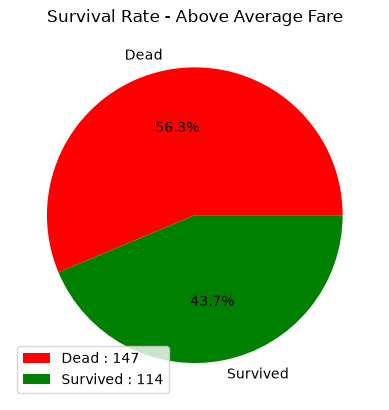

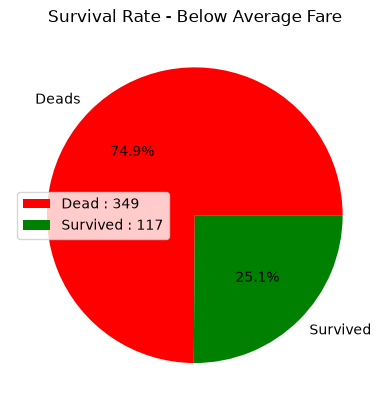

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,family_size,age_group,fare_group
0,0.0,3.0,male,22.0,1.0,0.0,7.250000,S,Third,man,True,NaN,Southampton,no,False,2.0,Young,below_average
2,1.0,3.0,female,26.0,0.0,0.0,7.925000,S,Third,woman,False,NaN,Southampton,yes,True,1.0,Young,below_average
4,0.0,3.0,male,35.0,0.0,0.0,8.050000,S,Third,man,True,NaN,Southampton,no,True,1.0,Young,below_average
5,0.0,3.0,male,NaN,0.0,0.0,8.458300,Q,Third,man,True,NaN,Queenstown,no,True,1.0,NaN,below_average
7,0.0,3.0,male,NaN,3.0,1.0,21.075001,S,Third,child,False,NaN,Southampton,no,False,5.0,NaN,above_average
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0.0,2.0,male,27.0,0.0,0.0,13.000000,S,Second,man,True,NaN,Southampton,no,True,1.0,Young,below_average
887,1.0,1.0,female,19.0,0.0,0.0,30.000000,S,First,woman,False,B,Southampton,yes,True,1.0,Young,above_average
888,0.0,3.0,female,NaN,1.0,2.0,23.450001,S,Third,woman,False,NaN,Southampton,no,False,4.0,NaN,above_average
889,1.0,1.0,male,26.0,0.0,0.0,30.000000,C,First,man,True,C,Cherbourg,yes,True,1.0,Young,above_average


In [73]:
if df["fare"].isna().sum()>0:
    df = df.dropna(subset = "fare")
    
above_average = df[df["fare"]>=df["fare"].mean()]
below_average = df[df["fare"]<df["fare"].mean()]

above_average_dead = (above_average["survived"]==0).sum()
above_average_survived = (above_average["survived"]==1).sum()

below_average_dead = (below_average["survived"]==0).sum()
below_average_survived = (below_average["survived"]==1).sum()

plt.pie([above_average_dead , above_average_survived], labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - Above Average Fare")
plt.legend(labels = [f"Dead : {above_average_dead} " , f"Survived : {above_average_survived}"])
plt.show()

plt.pie([below_average_dead , below_average_survived] , labels = ["Deads" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - Below Average Fare")
plt.legend(labels =  [f"Dead : {below_average_dead} " , f"Survived : {below_average_survived}"])
plt.show()

In [ ]:
Survival Rate - pclass

Survival Rate - pclass_1 :


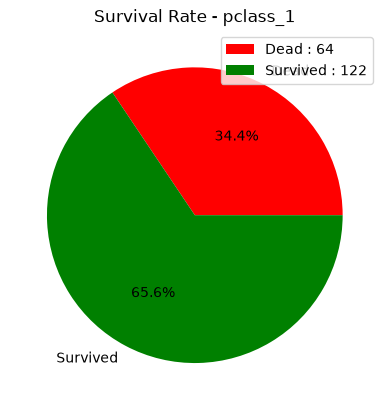

Survival Rate - pclass_2 :


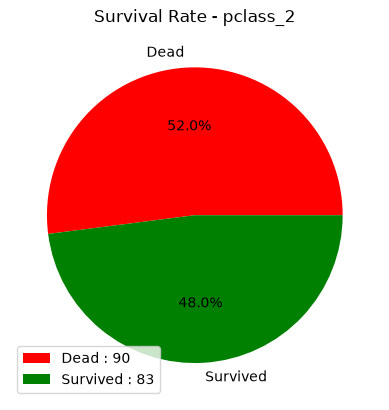

Survival Rate - pclass_3 :


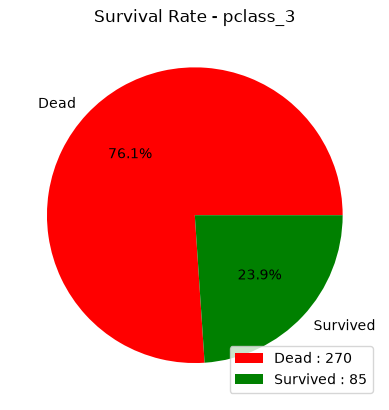

In [16]:
if df["pclass"].isna().sum()>0:
    df = df.dropna(subset = "pclass")
    

pclass_1 = df[df["pclass"] == 1]
pclass_2 = df[df["pclass"] == 2]
pclass_3 = df[df["pclass"] == 3]

pclass_1_dead = (pclass_1["survived"] == 0).sum()
pclass_1_survived = (pclass_1["survived"] == 1).sum()

pclass_2_dead = (pclass_2["survived"] == 0).sum()
pclass_2_survived = (pclass_2["survived"] == 1).sum()

pclass_3_dead = (pclass_3["survived"] == 0).sum()
pclass_3_survived = (pclass_3["survived"] == 1).sum()


print("Survival Rate - pclass_1 :")

plt.pie([pclass_1_dead , pclass_1_survived] , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - pclass_1")
plt.legend(labels = [f"Dead : {pclass_1_dead} " , f"Survived : {pclass_1_survived}"])
plt.show()

print("Survival Rate - pclass_2 :")

plt.pie([pclass_2_dead , pclass_2_survived] , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - pclass_2")
plt.legend(labels = [f"Dead : {pclass_2_dead} " , f"Survived : {pclass_2_survived}"])
plt.show()

print("Survival Rate - pclass_3 :")

plt.pie([pclass_3_dead , pclass_3_survived] , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - pclass_3")
plt.legend(labels = [f"Dead : {pclass_3_dead} " , f"Survived : {pclass_3_survived}"])
plt.show()

Survival Rate - Age

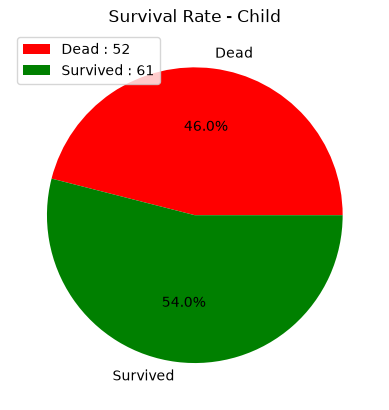

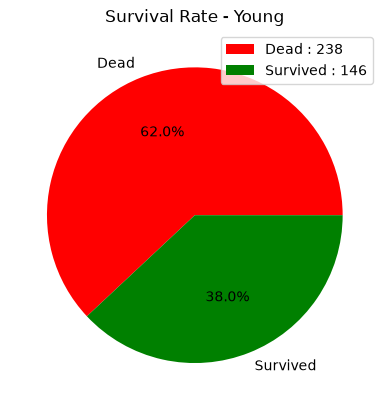

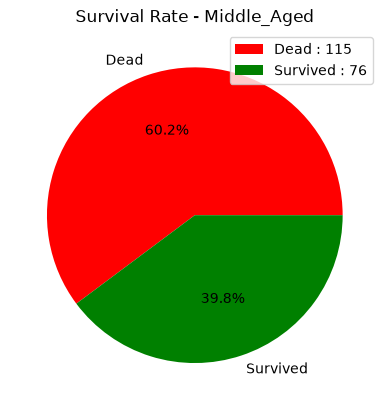

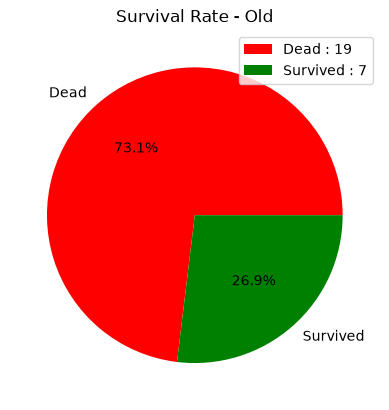

In [52]:
if df["age"].isna().sum()>0:
    df = df.dropna(subset = ["age"])

child = df[df["age"]<18]
Young =df[ (df["age"]>=18) & (df["age"]<=35)]
Middle_Aged = df[(df["age"]>=36) & (df["age"]<=59)]
old = df[df["age"]>=60]

dead_child = (child["survived"] == 0).sum()
survived_child = (child["survived"] == 1).sum()

dead_Young = (Young["survived"] == 0).sum()
survived_Young = (Young["survived"] == 1).sum()

dead_Middle_Aged = (Middle_Aged["survived"] == 0).sum()
survived_Middle_Aged = (Middle_Aged["survived"] == 1).sum()

dead_old = (old["survived"] == 0).sum()
survived_old = (old["survived"] == 1).sum()

plt.pie([dead_child , survived_child] , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - Child")
plt.legend(labels = [f"Dead : {dead_child}" , f"Survived : {survived_child}"])
plt.show()

plt.pie([dead_Young , survived_Young] , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - Young")
plt.legend(labels = [f"Dead : {dead_Young}" , f"Survived : {survived_Young}"])
plt.show()

plt.pie([dead_Middle_Aged , survived_Middle_Aged] , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - Middle_Aged")
plt.legend(labels = [f"Dead : {dead_Middle_Aged}" , f"Survived : {survived_Middle_Aged}"])
plt.show()

plt.pie([dead_old , survived_old] , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - Old")
plt.legend(labels = [f"Dead : {dead_old}" , f"Survived : {survived_old}"])
plt.show()

In [78]:
colums_df = df.columns

for i in colums_df:

    if df[i].dtype == "int64":

        if df[i].min() >= 0 and df[i].max() <= 255:
            df[i] = df[i].astype("uint8")

        elif df[i].min() >= 0 and df[i].max() <= 65535:
            df[i] = df[i].astype("uint16")

        elif df[i].min() >= 0 and df[i].max() <= 4294967295:
            df[i] = df[i].astype("uint32")

        elif df[i].min() >= 0 and df[i].max() <= 18446744073709551615:
            df[i] = df[i].astype("uint64")

    elif df[i].dtype == "float64":
        df[i] = df[i].astype("float32")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    uint8   
 1   pclass       891 non-null    uint8   
 2   sex          891 non-null    str     
 3   age          714 non-null    float32 
 4   sibsp        891 non-null    uint8   
 5   parch        891 non-null    uint8   
 6   fare         891 non-null    float32 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float32(2), str(5), uint8(4)
memory usage: 49.3 KB


In [59]:
survived_check = ((df["survived"] == 0 )& (df["alive"] == "no")) | ((df["survived"] == 1 )& (df["alive"] == "yes"))
pclass_check = (df["pclass"]>=1) | (df["pclass"]<=3)
sex_check = ((df["sex"] == "male") & (df["who"] == "men")) | ((df["sex"] == "female")&(df["who"] == "woman"))
std_age = np.std(df["age"])

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True
